# ShopperSense · 03 / Six-input models, cell by cell

This is the **actual training code**, separated into explained cells for the final submission. It fits the majority baseline, Logistic Regression, Decision Tree and Random Forest on the supplied dataset; performs the production parameter searches; selects using validation only; and reproduces the deployed six-input model's metrics.

**Current features:** ProductRelated, ProductRelated_Duration, Informational, Informational_Duration, VisitorType and Weekend. Administrative / Administrative_Duration were removed from the practical predictor at the user's request. The original CSV and earlier 17-feature research are preserved.

**Question:** Can these six recorded browsing-session features help identify purchases? One row is a session; Revenue is the known historical outcome. This is not validated early-session or cross-store forecasting. The historical test partition is reused from the earlier project, not a new external validation.

Run from this repository's root or `notebooks/`, with the environment in README installed. Run `python -m src.predictor.train` first to generate the production artifacts this notebook checks. No hidden cell state is required. The source generator copies the production preprocessing, metric and selection functions into visible code cells; the model cells below explicitly show each estimator, parameter grid and `.fit(...)` call.

## Cell 1 — Imports and project location
These are standard tabular classification libraries. The root-path setup makes shared project definitions accessible when Jupyter starts inside `notebooks/`.

In [1]:
from pathlib import Path
import sys, json, hashlib, warnings
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'src').is_dir(), 'Start from the project root or notebooks/'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.config import MODEL_ORDER
from src.predictor import train as production
SEED = 42
OUTPUT = ROOT / 'results' / 'predictor'
def saved(name):
    return json.loads((OUTPUT / name).read_text(encoding='utf-8'))

## Cell 2 — Read the supplied real CSV
The checksum identifies the exact raw file. We do not create training data, delete rows or replace missing outcomes. UCI attribution: Sakar & Kastro (2018), DOI 10.24432/C5F88Q, CC BY 4.0.

In [2]:
data_path = ROOT / 'data/raw/online_shoppers_intention.csv'
raw = pd.read_csv(data_path)
data_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
manifest = json.loads((ROOT / 'results/data_manifest.json').read_text())
assert data_hash == manifest['sha256']
print('Rows and columns:', raw.shape)
print('SHA-256:', data_hash)
display(raw.head())

Rows and columns: (12330, 18)
SHA-256: b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## Cell 3 — Explicit inputs and target
Only these six fields are passed to the pipelines. We do not merely hide account fields in the form: they are absent from X. Revenue and row IDs also never enter X. VisitorType is categorical; Weekend is explicit 0/1. The raw 18-column source stays unchanged.

In [3]:
NUMERIC = ['ProductRelated', 'ProductRelated_Duration', 'Informational',
           'Informational_Duration', 'Weekend']
CATEGORICAL = ['VisitorType']
FEATURES = NUMERIC + CATEGORICAL
assert FEATURES == production.FEATURES
assert not {'Administrative','Administrative_Duration','PageValues','Revenue','source_row_id'} & set(FEATURES)
X = raw[FEATURES].copy()
X['VisitorType'] = X['VisitorType'].astype(object)
boolean_map = {'true': 1, 'false': 0, '1': 1, '0': 0}
X['Weekend'] = X['Weekend'].astype(str).str.lower().map(boolean_map)
y = raw['Revenue'].astype(str).str.lower().map(boolean_map)
assert not X.isna().any().any() and not y.isna().any()
y = y.astype(int)
X['Weekend'] = X['Weekend'].astype(int)
display(pd.DataFrame({'source_column': FEATURES,
                      'meaning': ['Product page count','Product page seconds','Information page count',
                                  'Information page seconds','Weekend flag','Visitor category']}))
display(y.value_counts().rename(index={0:'No purchase',1:'Purchase'}))

,source_column,meaning
0,ProductRelated,Product page count
1,ProductRelated_Duration,Product page seconds
2,Informational,Information page count
3,Informational_Duration,Information page seconds
4,Weekend,Weekend flag
5,VisitorType,Visitor category


Revenue
No purchase    10422
Purchase        1908
Name: count, dtype: int64

## Cell 4 — Reproduce and verify the saved stratified splits
First reserve 15% test, then take 15/85 of the remainder for validation, both stratified with seed 42. Assert the exact source row order matches the production split. The same rows make the six-versus-eight comparison interpretable.

In [4]:
remaining_ids, test_ids = train_test_split(X.index.to_numpy(), test_size=0.15,
                                           stratify=y, random_state=SEED)
train_ids, validation_ids = train_test_split(remaining_ids, test_size=15/85,
                                           stratify=y.loc[remaining_ids], random_state=SEED)
split = json.loads((ROOT / 'results/splits.json').read_text())
assert split['source_sha256'] == data_hash
parts = {'train': train_ids, 'validation': validation_ids, 'test': test_ids}
for name, ids in parts.items():
    assert ids.tolist() == split['partitions'][name]['source_row_ids']
all_ids = np.concatenate(list(parts.values()))
assert len(all_ids) == len(set(all_ids)) == len(raw)
X_train, y_train = X.loc[train_ids], y.loc[train_ids]
X_validation, y_validation = X.loc[validation_ids], y.loc[validation_ids]
X_test, y_test = X.loc[test_ids], y.loc[test_ids]
display(pd.DataFrame([{'partition':name,'sessions':len(ids),'purchases':int(y.loc[ids].sum())}
                      for name,ids in parts.items()]))

,partition,sessions,purchases
0,train,8630,1336
1,validation,1850,286
2,test,1850,286


## Cell 5 — The production preprocessing code
This function is copied from `src/predictor/train.py`. Median imputation and categorical vocabulary are learned inside each training fold. StandardScaler is used only for Logistic Regression. The tree models retain numeric scale. No class weights or resampling are used.

In [5]:
def preprocess(scale=False):
    steps = [('impute', SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('scale', StandardScaler()))
    return ColumnTransformer([
        ('numeric', Pipeline(steps), NUMERIC),
        ('category', Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='__missing__')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), CATEGORICAL),
    ], remainder='drop')

## Cell 6 — The production metric function
AP ranks purchase scores across thresholds; it is not trapezoidal PR-AUC. Precision is TP/(TP+FP), recall TP/(TP+FN), and F1 balances them. Undefined precision with no predicted buyers is displayed as 0 by the declared convention.

In [6]:
def metrics(y, scores, threshold=.5):
    y, scores = np.asarray(y), np.asarray(scores, dtype=float)
    if y.ndim != 1 or scores.ndim != 1 or len(y) == 0 or not np.isin(y, [0, 1]).all():
        raise ValueError('Labels must be a nonempty binary array')
    if not np.isfinite(threshold) or not 0 <= threshold <= 1:
        raise ValueError('Threshold must be finite and within [0,1]')
    if len(y) != len(scores) or not np.isfinite(scores).all() or ((scores < 0) | (scores > 1)).any():
        raise ValueError('Scores must be finite, in [0,1], and aligned to labels')
    predicted = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    return {
        'threshold': float(threshold), 'support': len(y), 'purchases': int(y.sum()),
        'predicted_purchases': int(predicted.sum()),
        'precision': float(precision_score(y, predicted, zero_division=0)),
        'recall': float(recall_score(y, predicted, zero_division=0)),
        'f1': float(f1_score(y, predicted, zero_division=0)),
        'ap': float(average_precision_score(y, scores)) if y.sum() else None,
        'roc_auc': float(roc_auc_score(y, scores)) if len(np.unique(y)) == 2 else None,
        'accuracy': float(accuracy_score(y, predicted)),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
        'precision_defined': bool(predicted.sum()), 'recall_defined': bool(y.sum()),
    }

## Cell 7 — Common training-only cross-validation
Every learned classifier uses the same three shuffled stratified folds and AP objective. An unresolved convergence warning stops execution. Model and threshold choices later use validation, never test outcomes.

In [7]:
warnings.filterwarnings('error', category=ConvergenceWarning)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
models, searches = {}, {}
search_options = dict(scoring='average_precision', cv=cv, refit=True,
                      n_jobs=1, return_train_score=True, error_score='raise')

## Cell 8 — Majority baseline: actual fit code
Always predict no purchase. This exposes why accuracy can look high while buyer recall is zero. There is no hyperparameter search for this reference.

In [8]:
dummy_pipeline = Pipeline([
    ('preprocess', preprocess()),
    ('model', DummyClassifier(strategy='most_frequent', random_state=SEED))
])
dummy_pipeline.fit(X_train, y_train)
models['Dummy'] = dummy_pipeline
print('Baseline fitted only on training sessions.')

Baseline fitted only on training sessions.


## Cell 9 — Logistic Regression: actual fit and search code
A regularized linear log-odds model. Scaling makes regularization comparable across units. C=[0.1,1,10] is a deliberately small search; the best candidate is refitted on all training rows, with no validation refit.

In [9]:
logistic_pipeline = Pipeline([
    ('preprocess', preprocess(scale=True)),
    ('model', LogisticRegression(max_iter=2000, random_state=SEED))
])
logistic_search = GridSearchCV(logistic_pipeline, {'model__C':[0.1,1,10]}, **search_options)
logistic_search.fit(X_train, y_train)
models['Logistic Regression'] = logistic_search.best_estimator_
searches['Logistic Regression'] = logistic_search
print('Selected training-CV parameters:', logistic_search.best_params_)
display(pd.DataFrame(logistic_search.cv_results_)[['params','mean_test_score','std_test_score']])

Selected training-CV parameters: {'model__C': 0.1}


,params,mean_test_score,std_test_score
0,{'model__C': 0.1},0.261485,0.006194
1,{'model__C': 1},0.260963,0.005923
2,{'model__C': 10},0.260568,0.005659


## Cell 10 — Decision Tree: actual fit and search code
A tree learns nonlinear feature-threshold rules. Limiting depth and requiring larger leaves reduce overfitting. Six candidates cover depths 3,5,8 and minimum leaf sizes 5,20. Trees do not require numeric scaling.

In [10]:
tree_pipeline = Pipeline([
    ('preprocess', preprocess()),
    ('model', DecisionTreeClassifier(random_state=SEED))
])
tree_grid = {'model__max_depth':[3,5,8], 'model__min_samples_leaf':[5,20]}
tree_search = GridSearchCV(tree_pipeline, tree_grid, **search_options)
tree_search.fit(X_train, y_train)
models['Decision Tree'] = tree_search.best_estimator_
searches['Decision Tree'] = tree_search
print('Selected training-CV parameters:', tree_search.best_params_)
display(pd.DataFrame(tree_search.cv_results_)[['params','mean_test_score','std_test_score']])

Selected training-CV parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 20}


,params,mean_test_score,std_test_score
0,"{'model__max_depth': 3, 'model__min_samples_le...",0.245866,0.009054
1,"{'model__max_depth': 3, 'model__min_samples_le...",0.246469,0.008435
2,"{'model__max_depth': 5, 'model__min_samples_le...",0.255148,0.013108
3,"{'model__max_depth': 5, 'model__min_samples_le...",0.257190,0.017511
4,"{'model__max_depth': 8, 'model__min_samples_le...",0.234524,0.008961
5,"{'model__max_depth': 8, 'model__min_samples_le...",0.242961,0.020419


## Cell 11 — Random Forest: actual fit and search code
Average 150 randomized trees to reduce single-tree variance. This captures nonlinear patterns but is less directly interpretable. The bounded grid compares depth 8/unbounded and minimum leaf sizes 2/10.

In [11]:
forest_pipeline = Pipeline([
    ('preprocess', preprocess()),
    ('model', RandomForestClassifier(n_estimators=150, random_state=SEED, n_jobs=1))
])
forest_grid = {'model__max_depth':[8,None], 'model__min_samples_leaf':[2,10]}
forest_search = GridSearchCV(forest_pipeline, forest_grid, **search_options)
forest_search.fit(X_train, y_train)
models['Random Forest'] = forest_search.best_estimator_
searches['Random Forest'] = forest_search
print('Selected training-CV parameters:', forest_search.best_params_)
display(pd.DataFrame(forest_search.cv_results_)[['params','mean_test_score','std_test_score']])

Selected training-CV parameters: {'model__max_depth': 8, 'model__min_samples_leaf': 10}


,params,mean_test_score,std_test_score
0,"{'model__max_depth': 8, 'model__min_samples_le...",0.281468,0.011655
1,"{'model__max_depth': 8, 'model__min_samples_le...",0.283489,0.015190
2,"{'model__max_depth': None, 'model__min_samples...",0.242865,0.009724
3,"{'model__max_depth': None, 'model__min_samples...",0.279145,0.011877


## Cell 12 — Inspect every candidate and fold score
All 13 learned-model candidates and three test-fold AP scores are available. CV test folds are within training, not the held-out project test partition.

In [12]:
cv_tables = []
for name, search in searches.items():
    table = pd.DataFrame(search.cv_results_)
    table.insert(0,'model',name)
    cv_tables.append(table)
all_cv = pd.concat(cv_tables, ignore_index=True)
display(all_cv[['model','params','split0_test_score','split1_test_score','split2_test_score',
                'mean_test_score','std_test_score','rank_test_score']])
assert len(all_cv) == 13

,model,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
0,Logistic Regression,{'model__C': 0.1},0.253734,0.268894,0.261828,0.261485,0.006194,1
1,Logistic Regression,{'model__C': 1},0.253496,0.267985,0.261410,0.260963,0.005923,2
2,Logistic Regression,{'model__C': 10},0.253331,0.267145,0.261228,0.260568,0.005659,3
3,Decision Tree,"{'model__max_depth': 3, 'model__min_samples_le...",0.243280,0.236299,0.258019,0.245866,0.009054,4
4,Decision Tree,"{'model__max_depth': 3, 'model__min_samples_le...",0.243280,0.238109,0.258019,0.246469,0.008435,3
5,Decision Tree,"{'model__max_depth': 5, 'model__min_samples_le...",0.241139,0.251639,0.272666,0.255148,0.013108,2
6,Decision Tree,"{'model__max_depth': 5, 'model__min_samples_le...",0.240742,0.249380,0.281447,0.257190,0.017511,1
7,Decision Tree,"{'model__max_depth': 8, 'model__min_samples_le...",0.225530,0.231288,0.246753,0.234524,0.008961,6
8,Decision Tree,"{'model__max_depth': 8, 'model__min_samples_le...",0.215256,0.249762,0.263865,0.242961,0.020419,5
9,Random Forest,"{'model__max_depth': 8, 'model__min_samples_le...",0.268573,0.279023,0.296807,0.281468,0.011655,2


## Cell 13 — Validation comparison
Evaluate the four fitted models at 0.50. For compatibility with the shared selection helper, `feature_set=full` means all **six inputs in this condition**, not the earlier 17-feature research benchmark. Condition names distinguish these results.

In [13]:
validation_records = []
for name, fitted in models.items():
    score = fitted.predict_proba(X_validation)[:,1]
    validation_records.append({'model':name, 'feature_set':'full',
                               'condition':'six_observable_inputs','partition':'validation',
                               **metrics(y_validation, score, 0.5)})
validation_table = pd.DataFrame(validation_records)
display(validation_table[['model','ap','roc_auc','precision','recall','f1','accuracy','tp','fp','fn','tn']])
expected_validation = pd.read_csv(OUTPUT/'validation_metrics.csv')
np.testing.assert_allclose(validation_table.ap, expected_validation.ap, atol=1e-12)

,model,ap,roc_auc,precision,recall,f1,accuracy,tp,fp,fn,tn
0,Dummy,0.154595,0.500000,0.000000,0.000000,0.000000,0.845405,0,0,286,1564
1,Logistic Regression,0.253894,0.682359,0.285714,0.013986,0.026667,0.842162,4,10,282,1554
2,Decision Tree,0.264238,0.702312,0.372549,0.066434,0.112760,0.838378,19,32,267,1532
3,Random Forest,0.279134,0.708185,0.000000,0.000000,0.000000,0.845405,0,0,286,1564


## Cell 14 — The production validation-only decision functions
Choose highest validation AP; within 0.005 of the highest, prefer LR, then Tree, then Forest. For the selected model maximize validation F1 on 0.05..0.95 with 0.01 steps; ties use the larger threshold. These functions accept no test data.

In [14]:
def choose_model(validation_records):
    eligible = [r for r in validation_records if r['feature_set'] == 'full' and r['model'] in MODEL_ORDER]
    top = max(r['ap'] for r in eligible)
    return min((r for r in eligible if top-r['ap'] <= .005), key=lambda r: MODEL_ORDER.index(r['model']))['model']


def choose_threshold(validation_y, validation_scores):
    grid = [metrics(validation_y, validation_scores, step/100) for step in range(5, 96)]
    best = max(grid, key=lambda r: (r['f1'], r['threshold']))
    return best['threshold'], grid

## Cell 15 — Freeze before test evaluation
The production decision was saved before its test evaluation. This notebook reproduces it and writes a separate notebook decision record; it does not overwrite production selection. No model is refitted on validation.

In [15]:
selected_name = choose_model(validation_records)
selected_model = models[selected_name]
validation_scores = selected_model.predict_proba(X_validation)[:,1]
threshold, threshold_grid = choose_threshold(y_validation, validation_scores)
production_decision = saved('selection.json')
assert selected_name == production_decision['model']
assert threshold == production_decision['threshold']
decision = {'model':selected_name, 'threshold':threshold, 'features':FEATURES,
            'parameters':searches[selected_name].best_params_,
            'frozen_at_utc':datetime.now(timezone.utc).isoformat(),
            'purpose':'Notebook reproduction; no changes to the production decision'}
(OUTPUT/'notebook_decision.json').write_text(json.dumps(decision,indent=2))
display(pd.Series(decision))

model                                                Random Forest
threshold                                                     0.12
features         [ProductRelated, ProductRelated_Duration, Info...
parameters       {'model__max_depth': 8, 'model__min_samples_le...
frozen_at_utc                     2026-11-16T16:51:59.383667+00:00
purpose          Notebook reproduction; no changes to the produ...
dtype: object

## Cell 16 — Final frozen test comparison
Compare all four models at 0.50 and the selected model additionally at its frozen threshold. Scores are not calibrated purchase probabilities. This replays an existing historical split, not an independent new test. Exact agreement checks tie this notebook to the deployed model.

In [16]:
test_records = []
for name, fitted in models.items():
    scores = fitted.predict_proba(X_test)[:,1]
    cuts = [0.5,threshold] if name == selected_name and threshold != 0.5 else [0.5]
    for cut in cuts:
        test_records.append({'model':name,'feature_set':'six_observable_inputs','partition':'test',
                             **metrics(y_test,scores,cut)})
test_table = pd.DataFrame(test_records)
display(test_table[['model','threshold','ap','roc_auc','precision','recall','f1','accuracy','tp','fp','fn','tn']])
expected_test = pd.read_csv(OUTPUT/'test_metrics.csv')
for field in ['threshold','ap','roc_auc','precision','recall','f1','accuracy','tp','fp','fn','tn']:
    np.testing.assert_allclose(test_table[field], expected_test[field], atol=1e-12)
test_table.to_csv(OUTPUT/'notebook_metrics.csv',index=False)
official = test_table[(test_table.model==selected_name)&(test_table.threshold==threshold)].iloc[0]
print(f"Detected {int(official.tp)}/{int(official.purchases)} buyers; {int(official.fp)} false alarms among {int(official.predicted_purchases)} flagged sessions.")

,model,threshold,ap,roc_auc,precision,recall,f1,accuracy,tp,fp,fn,tn
0,Dummy,0.50,0.154595,0.500000,0.000000,0.000000,0.000000,0.845405,0,0,286,1564
1,Logistic Regression,0.50,0.282609,0.698915,0.375000,0.031469,0.058065,0.842162,9,15,277,1549
2,Decision Tree,0.50,0.268537,0.702840,0.300000,0.031469,0.056962,0.838919,9,21,277,1543
3,Random Forest,0.50,0.293266,0.714294,0.000000,0.000000,0.000000,0.845405,0,0,286,1564
4,Random Forest,0.12,0.293266,0.714294,0.215101,0.856643,0.343860,0.494595,245,894,41,670


Detected 245/286 buyers; 894 false alarms among 1139 flagged sessions.


## Cell 17 — Explain the mistakes visually
False positives are flagged sessions that did not purchase. False negatives are missed purchases. Counts and denominators make the limitations understandable to a nontechnical audience.

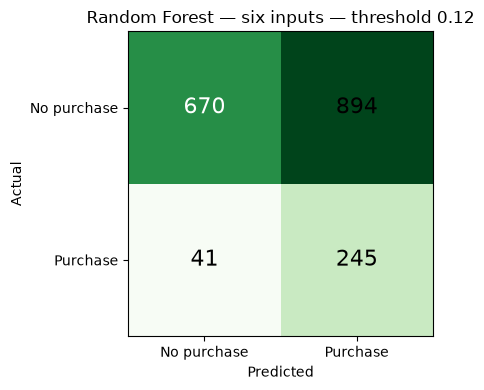

In [17]:
matrix = [[int(official.tn),int(official.fp)],[int(official.fn),int(official.tp)]]
fig, ax = plt.subplots(figsize=(5,4))
ax.imshow(matrix,cmap='Greens')
for row in range(2):
    for col in range(2):
        ax.text(col,row,str(matrix[row][col]),ha='center',va='center',fontsize=16,
                color='white' if row==0 and col==0 else 'black')
ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['No purchase','Purchase'],
       yticklabels=['No purchase','Purchase'],xlabel='Predicted',ylabel='Actual',
       title=f'{selected_name} — six inputs — threshold {threshold:.2f}')
plt.tight_layout();plt.show()

## Cell 18 — Measure removal of the account inputs
Do not claim these features were unimportant merely because they were removed. Compare the saved earlier eight-input condition and current six-input condition on the same row partitions. Each used the declared bounded search. Differences combine feature removal and any resulting training-CV parameter change; no statistical significance is claimed.

In [18]:
comparison = []
previous = ROOT/'results/predictor_previous_eight_inputs'
for partition in ['validation','test']:
    before = pd.read_csv(previous/f'{partition}_metrics.csv')
    after = pd.read_csv(OUTPUT/f'{partition}_metrics.csv')
    for name in ['Logistic Regression','Decision Tree','Random Forest']:
        old = before[(before.model==name)&(before.threshold==0.5)].iloc[0]
        new = after[(after.model==name)&(after.threshold==0.5)].iloc[0]
        comparison.append({'partition':partition,'model':name,'eight_input_ap':old.ap,
                           'six_input_ap':new.ap,'ap_change':new.ap-old.ap,
                           'eight_input_f1_at_050':old.f1,'six_input_f1_at_050':new.f1})
comparison_table = pd.DataFrame(comparison)
display(comparison_table)
comparison_table.to_csv(OUTPUT/'feature_removal_comparison.csv',index=False)

,partition,model,eight_input_ap,six_input_ap,ap_change,eight_input_f1_at_050,six_input_f1_at_050
0,validation,Logistic Regression,0.248380,0.253894,0.005514,0.026667,0.026667
1,validation,Decision Tree,0.264750,0.264238,-0.000512,0.006897,0.112760
2,validation,Random Forest,0.316011,0.279134,-0.036877,0.027304,0.000000
3,test,Logistic Regression,0.272770,0.282609,0.009839,0.058442,0.058065
4,test,Decision Tree,0.284062,0.268537,-0.015525,0.013699,0.056962
5,test,Random Forest,0.299416,0.293266,-0.006150,0.000000,0.000000


## Cell 19 — Predict a newly supplied six-input session
This constructed example is an inference demonstration, not training data or a performance claim. Account fields are absent from both this input and the model. Real users can supply the same six fields by form or CSV.

In [19]:
new_session = pd.DataFrame([{'ProductRelated':23,'ProductRelated_Duration':620,
                             'Informational':2,'Informational_Duration':40,
                             'Weekend':1,'VisitorType':'New_Visitor'}])[FEATURES]
score = float(selected_model.predict_proba(new_session)[0,1])
display(new_session)
print('Purchase score:',score)
print('Prediction:', 'Purchase predicted' if score>=threshold else 'No purchase predicted')
print('This score is not a guaranteed or calibrated probability.')

,ProductRelated,ProductRelated_Duration,Informational,Informational_Duration,Weekend,VisitorType
0,23,620,2,40,1,New_Visitor


Purchase score: 0.2332711519011321
Prediction: Purchase predicted
This score is not a guaranteed or calibrated probability.


## Cell 20 — Verify the browser export represents this fitted model
The export contains the exact preprocessing and fitted estimator used by the JavaScript engine. The separate Node check covers 3,703 Python/JS cases and CSV behavior. This cell verifies the notebook scores match the production test rows and the model uses only six original inputs.

In [20]:
exported = json.loads((ROOT/'docs/data/predictor.json').read_text())
notebook_export = production.export_model(selected_model)
assert notebook_export == exported['inference']
assert exported['feature_set'] == 'six_observable_inputs'
assert len(set(exported['inference']['transformed_feature_groups'])) == 6
predictions = pd.read_csv(OUTPUT/'predictions.csv',float_precision='round_trip')
test_predictions = predictions[predictions.partition=='test']
np.testing.assert_allclose(selected_model.predict_proba(X_test)[:,1],test_predictions.purchase_score,atol=1e-12)
print('Notebook model matches the deployed export and all saved test scores.')
print('Browser parity command: node tests/check_predictor.cjs')

Notebook model matches the deployed export and all saved test scores.
Browser parity command: node tests/check_predictor.cjs


C:\Desktop\College\SEM 5\ML\ML_course_project\.tmp\ipykernel_27296\2163920141.py:6: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  predictions = pd.read_csv(OUTPUT/'predictions.csv',float_precision='round_trip')


## What to explain in the submission

1. We predict a session's Revenue label from six observed browsing inputs.
2. The baseline, linear model, tree and forest have explicit fit/search cells above.
3. Preprocessing is learned inside training folds; validation selects model and threshold.
4. The fixed test comparison and error counts quantify performance without changing the decision.
5. Account/admin variables were removed to simplify the tool; measured before/after evidence is shown rather than an unsupported feature-importance claim.
6. The six-input predictor and original full-feature research benchmark are different conditions. They must not share performance claims.

**Limits:** one historical source, reused random split, no future-store or live-session validation, uncalibrated scores, and no causal/price/preference inference. False alarms and missed buyers remain.

**Credits:** We developed ShopperSense as a course project to explore how browsing behaviour relates to online purchase intent. We used AI tools, including ChatGPT and Codex, to assist with planning, coding, debugging, documentation, and website development. AI-generated code and suggestions supported the project. Human verification has been completed, and I have a complete understanding of the project. Responsibility for the submitted work, its interpretation, and its limitations remains mine. Dataset: Sakar & Kastro (2018), [UCI DOI 10.24432/C5F88Q](https://doi.org/10.24432/C5F88Q), CC BY 4.0.